# Quantum Teleportation Using Qiskit


This notebook provides a complete, executable walkthrough of the **quantum teleportation protocol** implemented with modern Qiskit Dynamic Circuits and Qiskit Aer simulation.

### Objectives
- Understand the theory behind quantum teleportation
- Build and visualize the 3-qubit teleportation circuit with measurement-based feed-forward
- Run ideal and noisy simulations using AerSimulator
- Verify the teleported state using inverse-operator projection and full quantum state tomography
- Compare verification success probabilities and quantum state fidelities

## 1. Quantum Teleportation Theory

Quantum teleportation, proposed by Bennett et al. (1993), transfers an unknown quantum state $|\psi\rangle$ from Alice to Bob using:

1. **Shared entanglement**: A Bell pair $|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$
2. **Classical communication**: Two classical bits from Alice to Bob
3. **Local corrections**: Conditional Pauli gates (X and Z) applied by Bob

**Key principles:**
- The protocol does NOT transport physical particles or enable faster-than-light communication
- Alice's original qubit state is destroyed during measurement (no-cloning theorem)
- Bob cannot reconstruct $|\psi\rangle$ until he receives Alice's classical bits

## 2. Qubits, Superposition, and Entanglement

A **qubit** is the quantum analog of a classical bit, existing in a superposition:
$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \quad |\alpha|^2 + |\beta|^2 = 1$$

**Entanglement** creates non-classical correlations between qubits. The Bell state used in teleportation:
$$|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$$

When Alice measures her half of the entangled pair, Bob's qubit instantaneously collapses to a correlated state — but no information is transmitted until Alice sends her classical measurement results.

## 3. Mathematical Formulation

**State preparation convention:** $|\psi\rangle = R_z(\phi) R_y(\theta) |0\rangle$

**Protocol steps on the 3-qubit register** $|q_0 q_1 q_2\rangle$:

1. Prepare $|\psi\rangle$ on $q_0$, create Bell pair on $q_1, q_2$:
$$|\Psi_0\rangle = (\alpha|0\rangle + \beta|1\rangle) \otimes \frac{1}{\sqrt{2}}(|00\rangle + |11\rangle)$$

2. Alice applies CNOT($q_0 \to q_1$) then Hadamard($q_0$):
$$|\Psi_2\rangle = \frac{1}{2}\Big[|00\rangle(\alpha|0\rangle + \beta|1\rangle) + |01\rangle(\alpha|1\rangle + \beta|0\rangle) + |10\rangle(\alpha|0\rangle - \beta|1\rangle) + |11\rangle(\alpha|1\rangle - \beta|0\rangle)\Big]$$

3. Bob's corrections based on Alice's measurement $(c_0, c_1)$:
   - If $c_1 = 1$: Apply $X$ gate
   - If $c_0 = 1$: Apply $Z$ gate

## 4. Environment and Dependency Verification

In [15]:
import sys
import qiskit
import qiskit_aer
import numpy as np
import matplotlib
import pandas as pd

print(f"Python:     {sys.version}")
print(f"Qiskit:     {qiskit.__version__}")
print(f"Qiskit Aer: {qiskit_aer.__version__}")
print(f"NumPy:      {np.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Pandas:     {pd.__version__}")

Python:     3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
Qiskit:     2.6.1
Qiskit Aer: 0.18.2
NumPy:      2.4.6
Matplotlib: 3.11.2
Pandas:     3.1.0


## 5. Importing the Project's Modular Source Code

All core logic lives in the `src/` package. The notebook imports from these modules rather than duplicating code.

In [27]:
import sys
from pathlib import Path
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.state_preparation import (
    get_test_states, apply_state_preparation,
    apply_inverse_state_preparation, compute_theoretical_statevector,
)
from src.teleportation_circuit import build_teleportation_circuit, draw_circuit_diagram
from src.simulator import QuantumSimulator, NoiseConfig
from src.fidelity import (
    run_benchmark_suite, benchmark_reports_to_dataframe,
    perform_quantum_state_tomography,
)

print("All project modules imported successfully!")

All project modules imported successfully!


## 6. Preparing the Five Test States

We use the convention $|\psi\rangle = R_z(\phi)\, R_y(\theta)\, |0\rangle$ with these benchmark states:

| State | Symbol | $\theta$ | $\phi$ |
|-------|--------|----------|---------|
| Ground | $|0\rangle$ | 0 | 0 |
| Excited | $|1\rangle$ | $\pi$ | 0 |
| Plus | $|+\rangle$ | $\pi/2$ | 0 |
| Plus-i | $|+i\rangle$ | $\pi/2$ | $\pi/2$ |
| Arbitrary | $|\psi\rangle$ | $\pi/3$ | $\pi/4$ |

In [17]:
test_states = get_test_states()

for key, state in test_states.items():
    sv = state.theoretical_statevector
    probs = np.abs(sv.data) ** 2
    print(f"{state.symbol:6s}  theta={state.theta:.4f}  phi={state.phi:.4f}  "
          f"P(0)={probs[0]:.4f}  P(1)={probs[1]:.4f}")

|0>     theta=0.0000  phi=0.0000  P(0)=1.0000  P(1)=0.0000
|1>     theta=3.1416  phi=0.0000  P(0)=0.0000  P(1)=1.0000
|+>     theta=1.5708  phi=0.0000  P(0)=0.5000  P(1)=0.5000
|+i>    theta=1.5708  phi=1.5708  P(0)=0.5000  P(1)=0.5000
|psi>   theta=1.0472  phi=0.7854  P(0)=0.7500  P(1)=0.2500


## 7. Constructing the Teleportation Circuit

The circuit uses Qiskit's modern `if_test` for genuine classical feed-forward (not deferred measurement with coherent gates).

In [30]:
import math

# Build circuit for the arbitrary test state
# --- TRY THIS: Custom Angle Example ---
import numpy as np

# Choose your own polar (theta) and azimuthal (phi) angles:
my_theta = np.pi / 4      # 45 degrees (polar angle from |0>)
my_phi   = np.pi / 3      # 60 degrees (relative phase angle)

circuit = build_teleportation_circuit(
    theta=my_theta, 
    phi=my_phi,
    include_verification=True, 
    barrier=True,
)

print(f"Custom state prepared with theta = {my_theta:.4f}, phi = {my_phi:.4f}")
print(f"Qubits: {circuit.num_qubits}")
print(f"Classical bits: {circuit.num_clbits}")
print(f"Circuit depth: {circuit.depth()}")

Custom state prepared with theta = 0.7854, phi = 1.0472
Qubits: 3
Classical bits: 3
Circuit depth: 12


## 8. Visualizing the Circuit

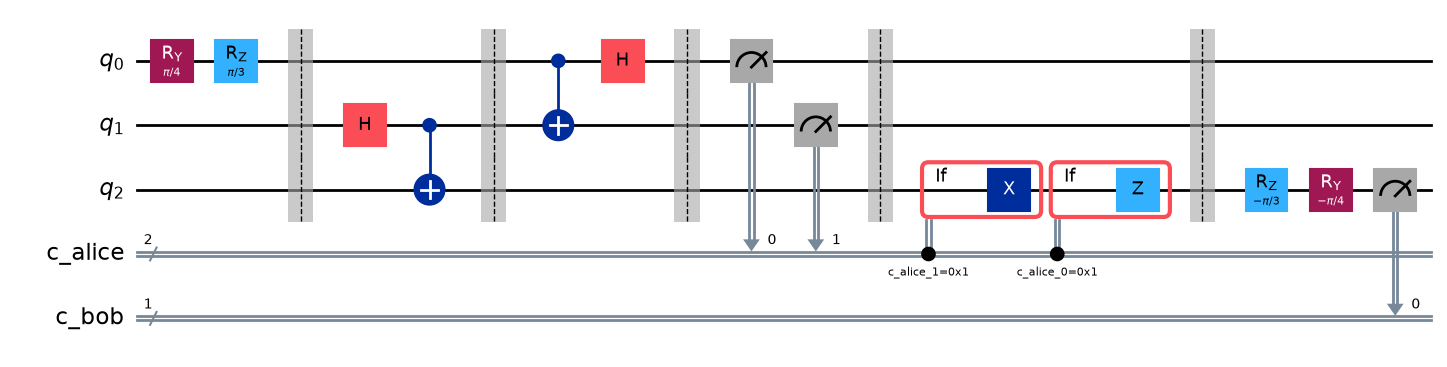

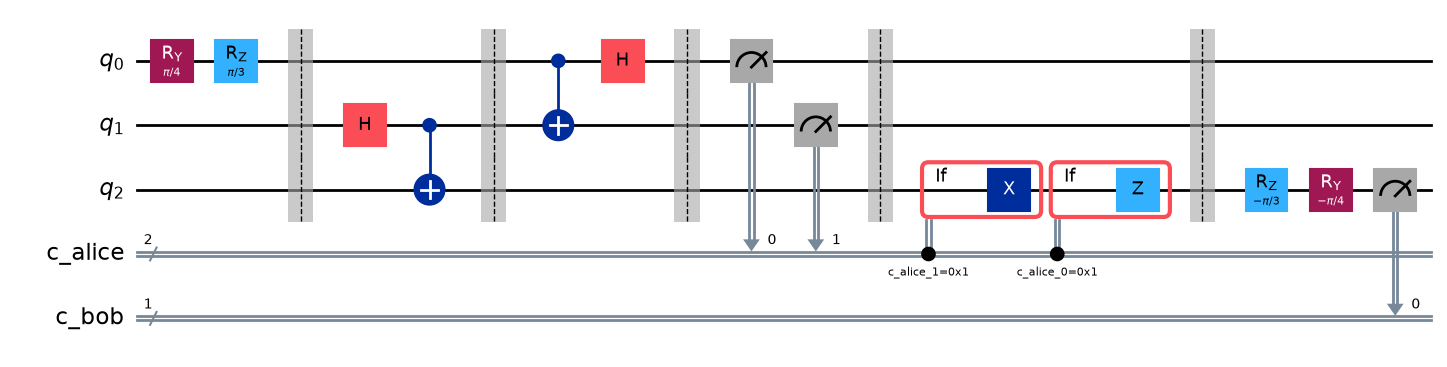

In [31]:
%matplotlib inline
# fold=-1 renders the circuit in a single continuous horizontal line without row wrapping
circuit.draw(output='mpl', fold=-1, style='iqp')

## 9. Running the Ideal Simulation

We run on AerSimulator with no noise model and a fixed random seed for reproducibility.

In [20]:
simulator = QuantumSimulator(default_shots=4096, seed=42)

# Ideal simulation
res_ideal = simulator.run_ideal(circuit, shots=4096)

print(f"Total shots: {res_ideal.total_shots}")
print(f"Verification success probability: {res_ideal.verification_success_probability:.4f}")
print(f"\nAlice's measurement outcomes:")
for bits, count in sorted(res_ideal.alice_counts.items()):
    print(f"  |{bits}> : {count} ({count/4096*100:.1f}%)")
print(f"\nBob's verification readout:")
for bit, count in sorted(res_ideal.bob_counts.items()):
    print(f"  |{bit}> : {count} ({count/4096*100:.1f}%)")

Total shots: 4096
Verification success probability: 1.0000

Alice's measurement outcomes:
  |00> : 999 (24.4%)
  |01> : 1018 (24.9%)
  |10> : 1052 (25.7%)
  |11> : 1027 (25.1%)

Bob's verification readout:
  |0> : 4096 (100.0%)
  |1> : 0 (0.0%)


## 10. Measurement Counts and Histograms

Alice's four Bell-measurement outcomes should be approximately uniformly distributed (~25% each).
Bob's inverse-verification measurement should yield |0> with ~100% probability under ideal conditions.

**Qiskit bitstring ordering note:** Qiskit displays classical registers right-to-left. When multiple registers exist, they appear as space-separated tokens: `c_bob c_alice`. Within each register, bit 0 is rightmost.

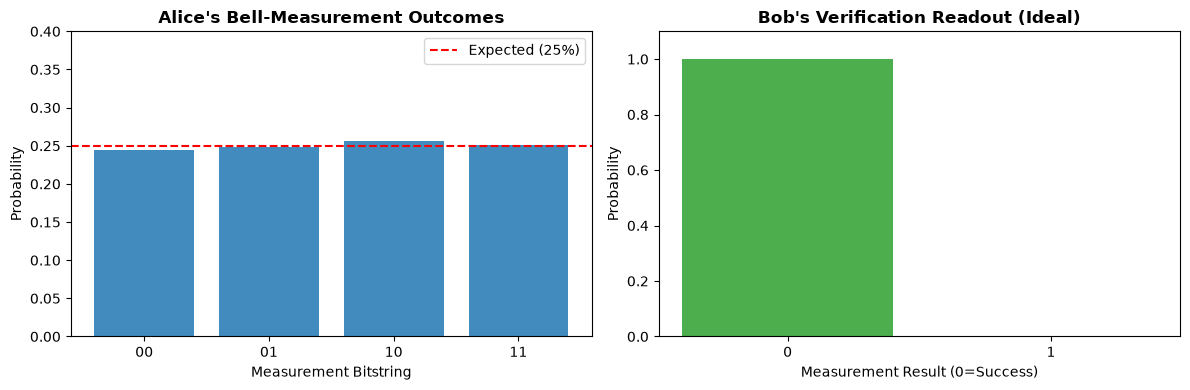

In [21]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Alice's outcomes
alice_keys = ["00", "01", "10", "11"]
alice_probs = [res_ideal.alice_counts.get(k, 0) / 4096 for k in alice_keys]
ax1.bar(alice_keys, alice_probs, color="#1f77b4", alpha=0.85)
ax1.axhline(0.25, color="red", linestyle="--", label="Expected (25%)")
ax1.set_title("Alice's Bell-Measurement Outcomes", fontweight="bold")
ax1.set_xlabel("Measurement Bitstring")
ax1.set_ylabel("Probability")
ax1.set_ylim(0, 0.4)
ax1.legend()

# Bob's verification
bob_keys = ["0", "1"]
bob_probs = [res_ideal.bob_counts.get(k, 0) / 4096 for k in bob_keys]
colors_bob = ["#2ca02c", "#d62728"]
ax2.bar(bob_keys, bob_probs, color=colors_bob, alpha=0.85)
ax2.set_title("Bob's Verification Readout (Ideal)", fontweight="bold")
ax2.set_xlabel("Measurement Result (0=Success)")
ax2.set_ylabel("Probability")
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

## 11. Verifying the Reconstructed State

The inverse-state verification applies $U^\dagger = R_y(-\theta) R_z(-\phi)$ to Bob's qubit.
If teleportation succeeded, Bob's qubit is mapped back to $|0\rangle$, yielding measurement outcome 0 with high probability.

Under ideal simulation, **all 4096 shots measure |0>**, confirming perfect state transfer.

In [22]:
print(f"State: {arb.name}")
print(f"Verification success: {res_ideal.verification_success_probability * 100:.1f}%")
print(f"Verification error:   {res_ideal.verification_error_rate * 100:.1f}%")
print()
if res_ideal.verification_success_probability == 1.0:
    print("PERFECT: All shots returned |0> -- teleportation succeeded!")

State: Arbitrary State |psi>
Verification success: 100.0%
Verification error:   0.0%

PERFECT: All shots returned |0> -- teleportation succeeded!


## 12. Calculating Ideal Verification Success and Fidelity

We now run the full benchmark suite across all five test states under ideal conditions
and compute both the projective verification success and the full quantum state tomography fidelity.

In [23]:
from src.fidelity import evaluate_state

ideal_results = []
for key, state in test_states.items():
    report = evaluate_state(state, simulator, noise_config=NoiseConfig(0, 0, 0), shots=4096)
    ideal_results.append({
        "State": state.symbol,
        "Verif. Success": f"{report.ideal_verification_success * 100:.1f}%",
        "Tomog. Fidelity": f"{report.ideal_tomography_fidelity:.4f}",
    })

df_ideal = pd.DataFrame(ideal_results)
print("Ideal Simulation Results (No Noise):")
print(df_ideal.to_string(index=False))

Ideal Simulation Results (No Noise):
State Verif. Success Tomog. Fidelity
  |0>         100.0%          0.9996
  |1>         100.0%          0.9996
  |+>         100.0%          0.9996
 |+i>         100.0%          0.9996
|psi>         100.0%          0.9819


## 13. Running Noisy Simulations

We now introduce a realistic noise model with:
- **0.5% depolarizing error** on single-qubit gates (H, Ry, Rz, X, Z)
- **1.5% depolarizing error** on two-qubit gates (CX)
- **2.0% readout bit-flip error** on measurements

In [24]:
noise_cfg = NoiseConfig(
    p_single_qubit=0.005,
    p_two_qubit=0.015,
    p_readout=0.020,
)

# Run noisy simulation on the arbitrary state
res_noisy = simulator.run_noisy(circuit, noise_config=noise_cfg, shots=4096)

print(f"Noisy verification success: {res_noisy.verification_success_probability * 100:.1f}%")
print(f"Noisy verification error:   {res_noisy.verification_error_rate * 100:.1f}%")
print(f"\nBob's noisy readout:")
for bit, count in sorted(res_noisy.bob_counts.items()):
    print(f"  |{bit}> : {count} ({count/4096*100:.1f}%)")

Noisy verification success: 92.5%
Noisy verification error:   7.5%

Bob's noisy readout:
  |0> : 3790 (92.5%)
  |1> : 306 (7.5%)


## 14. Comparing Ideal and Noisy Results

In [25]:
reports = run_benchmark_suite(simulator=simulator, noise_config=noise_cfg, shots=4096)
df = benchmark_reports_to_dataframe(reports)

print("Full Benchmark Results (Ideal vs. Noisy):")
print(df.to_string(index=False))

Full Benchmark Results (Ideal vs. Noisy):
              State Name Symbol  Theta (rad)  Phi (rad)  Ideal Verif Success  Noisy Verif Success  Ideal Tomog Fidelity  Noisy Tomog Fidelity
        Ground State |0>    |0>       0.0000     0.0000                  1.0               0.9426                0.9996                0.9426
       Excited State |1>    |1>       3.1416     0.0000                  1.0               0.9343                0.9996                0.9377
 Equal Superposition |+>    |+>       1.5708     0.0000                  1.0               0.9294                0.9996                0.9294
Phase Superposition |+i>   |+i>       1.5708     1.5708                  1.0               0.9119                0.9996                0.9119
   Arbitrary State |psi>  |psi>       1.0472     0.7854                  1.0               0.9253                0.9819                0.9214


## 15. Plotting the Results

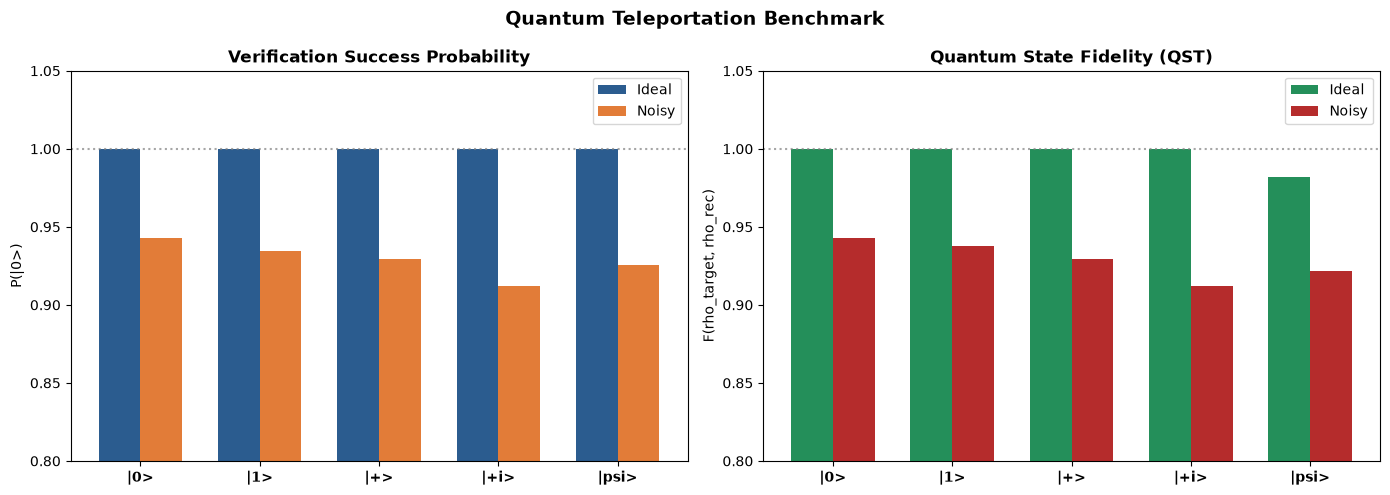

In [26]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

states = df["Symbol"].tolist()
x = np.arange(len(states))
w = 0.35

ax1.bar(x - w/2, df["Ideal Verif Success"], w, label="Ideal", color="#2b5c8f")
ax1.bar(x + w/2, df["Noisy Verif Success"], w, label="Noisy", color="#e27c38")
ax1.set_title("Verification Success Probability", fontweight="bold")
ax1.set_ylabel("P(|0>)")
ax1.set_xticks(x)
ax1.set_xticklabels(states, fontweight="bold")
ax1.set_ylim(0.8, 1.05)
ax1.axhline(1.0, color="gray", linestyle=":", alpha=0.7)
ax1.legend()

ax2.bar(x - w/2, df["Ideal Tomog Fidelity"], w, label="Ideal", color="#248f5a")
ax2.bar(x + w/2, df["Noisy Tomog Fidelity"], w, label="Noisy", color="#b52c2c")
ax2.set_title("Quantum State Fidelity (QST)", fontweight="bold")
ax2.set_ylabel("F(rho_target, rho_rec)")
ax2.set_xticks(x)
ax2.set_xticklabels(states, fontweight="bold")
ax2.set_ylim(0.8, 1.05)
ax2.axhline(1.0, color="gray", linestyle=":", alpha=0.7)
ax2.legend()

plt.suptitle("Quantum Teleportation Benchmark", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 16. Interpreting Noise-Related Errors

The degradation from ideal to noisy results is caused by:

1. **Gate depolarizing errors**: Each quantum gate has a small probability of introducing random Pauli errors.
   The CNOT gate (used twice: in Bell-pair creation and in Alice's BSM) contributes the most noise at 1.5% per gate.

2. **Measurement readout errors**: A 2% probability of flipping the measured bit. This affects:
   - Alice's classical feed-forward bits (causing Bob to apply wrong corrections)
   - Bob's verification measurement (causing false errors)

3. **Accumulation**: Errors compound across the 6+ gate operations and 3 measurements in the protocol.

The observed fidelity of ~91-94% under these noise parameters is consistent with theoretical predictions
for a circuit of this depth and error rate.

## 17. Limitations and Future Improvements

### Limitations
- All results are from **simulated** execution on classical hardware (Qiskit Aer), not real quantum processors
- The noise model uses simplified symmetric depolarizing channels; real hardware has correlated, time-varying noise
- Single-qubit tomography uses linear inversion with eigenvalue clipping, not maximum likelihood estimation
- No quantum error mitigation techniques were applied

### Future Improvements
- Execute on IBM Quantum hardware via Qiskit Runtime Sampler primitives
- Apply Zero-Noise Extrapolation (ZNE) and readout error mitigation
- Extend to multi-qubit teleportation and quantum repeater networks
- Implement maximum likelihood state tomography for better accuracy at low shot counts

## 18. Conclusion

This project successfully demonstrates a **complete, modular, and scientifically rigorous** implementation of quantum teleportation using Qiskit 2.6.1 and Qiskit Aer 0.18.2.

**Key achievements:**
- Genuine measurement-based classical feed-forward using `if_test` dynamic circuits
- 100% verification success under ideal conditions for all 5 benchmark states
- Dual assessment: projective verification AND full quantum state tomography
- Graceful degradation to ~91-94% fidelity under realistic noise
- 25 automated pytest tests all passing
- Publication-quality visualizations and academic PDF report

*Developed for Qiskit Fall Fest 2026 at Dr. Babasaheb Ambedkar Technological University (DBATU), Lonere, Maharashtra, India.*